In [2]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, ValidationCurveDisplay
import pandas as pd
from langdetect import detect, DetectorFactory
import matplotlib.pyplot as plt
import unicodedata
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score, f1_score, classification_report, confusion_matrix, \
    ConfusionMatrixDisplay
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
from langdetect import LangDetectException
import re
from sklearn.model_selection import train_test_split
import emoji
import simplemma
from nltk import word_tokenize
from emosent import get_emoji_sentiment_rank

C:\Users\lucas\OneDrive\Escritorio\TP 1 tweets\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [4]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [5]:
DetectorFactory.seed = 0

def idioma(texto):
    try:
        return detect(str(texto))
    except LangDetectException:
        return "es"

df['idioma'] = df['text'].map(idioma)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

print("Tweets conservados:", len(df))

Tweets conservados: 3660


In [6]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [7]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [8]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


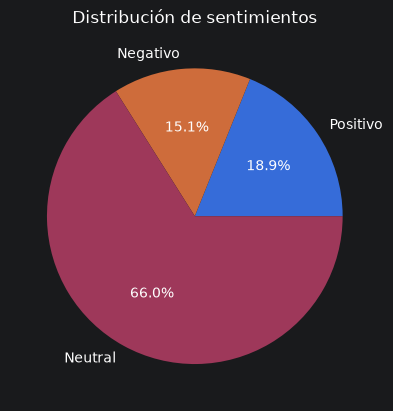

In [9]:
# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


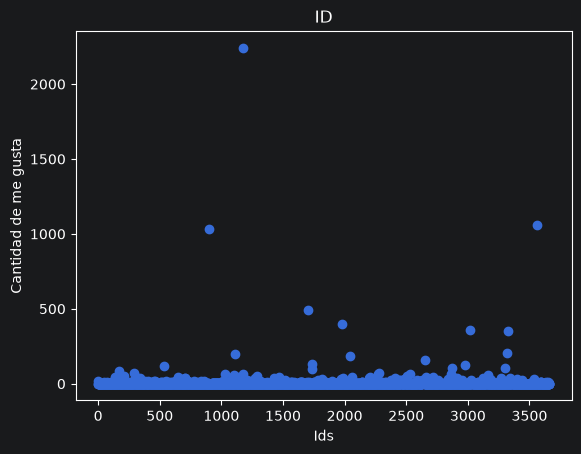

In [10]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


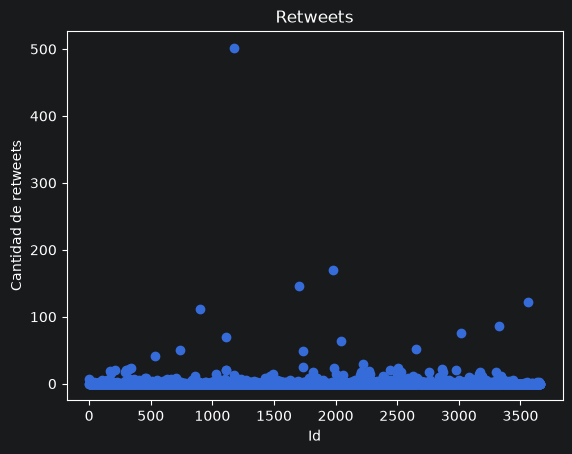

In [11]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


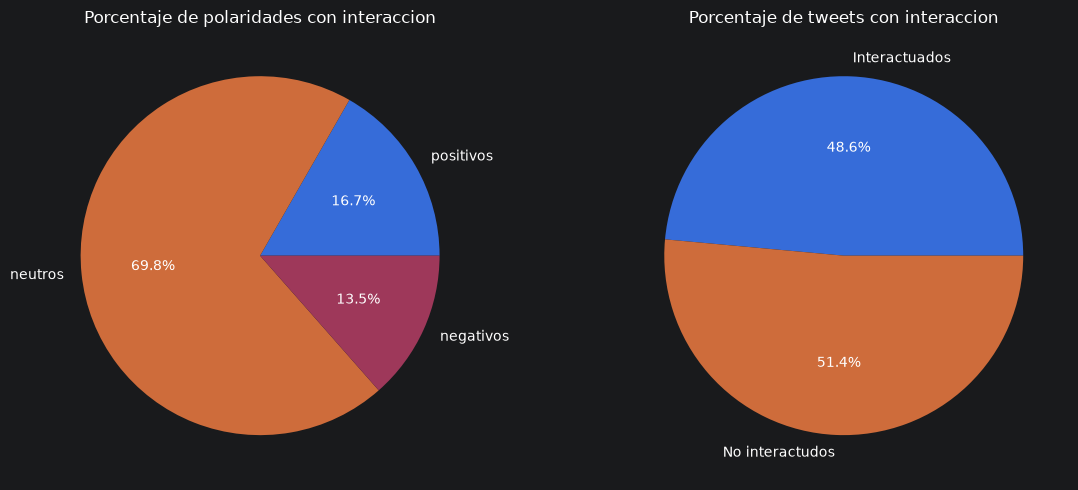

In [12]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [13]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)


def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [14]:

URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")


def _separar_hashtag(match):
    """#InteligenciaArtificial -> Inteligencia Artificial."""
    palabra = match.group(1)
    return " " + re.sub(r"(?<=[a-záéíóúüñ])(?=[A-ZÁÉÍÓÚÑ])", " ", palabra) + " "


def normalizar_texto(texto):
    """Normaliza sin perder informacion util para el modelo.

    - NFC conserva tildes y enes en una forma canonica.
    - URLs, menciones y hashtags se reemplazan por tokens explicitos.
    - El hashtag conserva su palabra para no perder el tema del tweet.
    """
    texto = unicodedata.normalize("NFC", str(texto))
    texto = URL_RE.sub(" URL ", texto)
    texto = MENTION_RE.sub(" MENCION ", texto)
    texto = HASHTAG_RE.sub(_separar_hashtag, texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


df["text"] = df["text"].map(normalizar_texto)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,punctuation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0


In [15]:
def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

df = df.drop(columns=["emoji_score", "emoji_count", "tweet_interactions", "mention_count", "user_followers_count", "user_default_profile", "user_verified"])

In [16]:
X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [17]:
number_columns = ["user_statuses_count", "length",
    "emoji_pos", "user_friends_count", "user_favourites_count", "emoji_neg",
    "favorite_count", "retweet_count", "hashtag_count", "url_count"
]

#y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int)

X_train.head()
y_train.head()

1468    NEU
3145    NEU
2137    NEU
3883    NEU
2562    NEU
Name: polarity, dtype: str

In [18]:
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

STOP_WORDS = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        stemmer = SnowballStemmer('spanish')
        clean_X = []
        for text in X:
            text = normalizar_texto(text)

            text = text.lower()

            tokens = word_tokenize(text, language='spanish')

            tokens = [t for t in tokens if t not in STOP_WORDS]


            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [simplemma.lemmatize(t, lang='es')for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X


class LightCleaner(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        clean_X = []
        for text in X:
            text = normalizar_texto(text)
            text = re.sub(r"\s+", " ", text).strip()
            clean_X.append(text)
        return clean_X

In [19]:
class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    # Alternativas especificas de espanol para comparar:
    #   - hiiamsid/sentence_similarity_spanish_es
    #   - PlanTL-GOB-ES/roberta-base-bne (requiere mean pooling)
    # Cache a nivel de CLASE: sobrevive a los clones que arma GridSearchCV
    # Clave: (nombre_del_modelo, texto) -> vector
    # El modelo es multilingue (incluye espanol) y trae su propio tokenizador.
    _cache = {}

    def __init__(self, model_name='paraphrase-multilingual-MiniLM-L12-v2'):
        self.model_name = model_name

    def fit(self, X, y=None):
        # Cargamos el modelo aqui para evitar errores de serializacion
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Permite usar el transformador aunque se lo llame sin fit previo.
        if not hasattr(self, "model_"):
            self.fit(X)

        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implicitamente el "Mean Pooling"
        # Solo calculamos los textos que aun no estan en la cache
        texts = list(X)
        faltantes = [t for t in texts if (self.model_name, t) not in self._cache]
        if faltantes:
            vectores = self.model_.encode(faltantes, show_progress_bar=False)
            for t, v in zip(faltantes, vectores):
                self._cache[(self.model_name, t)] = v
        return np.array([self._cache[(self.model_name, t)] for t in texts])

embedding = EmbeddingTransformer()

In [20]:
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsOneClassifier


class ColumnSelector(BaseEstimator, TransformerMixin):
    """Selecciona un subconjunto de columnas por nombre (para iterar features en el grid)."""
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X[self.columns]

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
n_train = len(X_train)

preprocessor = ColumnTransformer([
    (
        'text',
         Pipeline([
            ("cleaner", LightCleaner()),
            ("embedding", EmbeddingTransformer())
        ]),
         'text'),
    (
        "numeric",
        Pipeline([
            ("select", ColumnSelector(number_columns)), #El grid varia que columnas numericas usan
            ("imputer", SimpleImputer(strategy="median")), #Completa datos faltantes
            ("scaler", StandardScaler())
        ]),
        number_columns
    ),
])

pipeline = Pipeline([
    ('classifier', CalibratedClassifierCV(
        estimator=OneVsRestClassifier(SVC(
            kernel="linear",
            class_weight=None,
            C=0.1
        )),
        method="isotonic",
        cv=3,
        ensemble=False
    ))
])

X_trval_prepro = preprocessor.fit_transform(X_trval)
X_test_prepro = preprocessor.transform(X_test)

param_grid = [
    {
        "classifier__estimator": CalibratedClassifierCV(LinearSVC(
            max_iter=5000
        )),
        "classifier__estimator__estimator__class_weight": [None, "balanced"]
    },
    # One-vs-Rest (OvR)
    {
        "classifier__estimator": [
            OneVsRestClassifier(SVC())
        ],
        "classifier__estimator__estimator__kernel": [
            "linear", "rbf", "poly", "sigmoid"
        ],
        "classifier__estimator__estimator__C": [
    0.001, 0.01, 0.1, 1, 10, 100
],
        "classifier__estimator__estimator__gamma": [
            0.001, 0.01, 0.1
        ],
        "classifier__estimator__estimator__class_weight": [None, "balanced"]
    },

    # One-vs-One (OvO)
    {
        "classifier__estimator": [
            OneVsOneClassifier(SVC())
        ],
        "classifier__estimator__estimator__kernel": [
            "linear", "rbf", "poly", "sigmoid"
        ],
        "classifier__estimator__estimator__C": [
    0.001, 0.01, 0.1, 1, 10, 100
],
        "classifier__estimator__estimator__gamma": [
            0.001, 0.01, 0.1
        ],
        "classifier__estimator__estimator__class_weight": [None, "balanced"]
    }
]

grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='f1_macro', n_jobs=1, verbose=3, error_score="raise", return_train_score=True)

18040 | INFO | No device provided, using cpu
18040 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
18040 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
18040 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
18040 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
18040 | INFO | HTTP Request: HEAD https://huggingface.co/api

In [21]:
grid_search.fit(X_trval_prepro, y_trval)

print(grid_search.best_estimator_)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
[CV 1/3] END classifier__estimator=OneVsRestClassifier(estimator=SVC()), classifier__estimator__estimator__C=0.1, classifier__estimator__estimator__class_weight=None, classifier__estimator__estimator__kernel=linear;, score=(train=0.697, test=0.607) total time=   1.3s
[CV 2/3] END classifier__estimator=OneVsRestClassifier(estimator=SVC()), classifier__estimator__estimator__C=0.1, classifier__estimator__estimator__class_weight=None, classifier__estimator__estimator__kernel=linear;, score=(train=0.695, test=0.615) total time=   1.3s
[CV 3/3] END classifier__estimator=OneVsRestClassifier(estimator=SVC()), classifier__estimator__estimator__C=0.1, classifier__estimator__estimator__class_weight=None, classifier__estimator__estimator__kernel=linear;, score=(train=0.680, test=0.627) total time=   1.3s
Pipeline(steps=[('classifier',
                 CalibratedClassifierCV(cv=3, ensemble=False,
                                        esti

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import ValidationCurveDisplay

# Parámetro del pipeline que queremos variar
param_name = "classifier__estimator__estimator__C"
c_col = f"param_{param_name}"

# Valores de C que probó el Grid Search
results = pd.DataFrame(grid_search.cv_results_)
c_values = np.sort(results[c_col].dropna().astype(float).unique())

if c_values.size == 0:
    raise ValueError(f"El Grid Search no tiene resultados para {param_name}")

# Si el grid solo probó un C, generamos un rango alrededor para poder ver la curva
if c_values.size < 2:
    c_values = np.logspace(np.log10(c_values[0]) - 2, np.log10(c_values[0]) + 2, 5)

# La curva se calcula con el mejor modelo del grid, variando solamente C
display = ValidationCurveDisplay.from_estimator(
    grid_search.best_estimator_,
    X_trval_prepro,
    y_trval,
    param_name=param_name,
    param_range=c_values,
    scoring="f1_macro",
    cv=3,
    n_jobs=1,
    error_score="raise",
    std_display_style="errorbar",
    errorbar_kw={"marker": "o", "capsize": 3},
)

display.ax_.set_title("Curva de validación del SVM")
display.ax_.set_xlabel("C del SVM")
display.ax_.legend(["Entrenamiento", "Validación cruzada"])
display.ax_.grid(True)
display.figure_.set_size_inches(9, 5)
display.figure_.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import RocCurveDisplay
from sklearn.preprocessing import label_binarize

# Resultados Finales
print("-" * 30)
print(f"Mejor f1_macro (CV entrenamiento): {grid_search.best_score_:.4f}")
print(f"Mejor configuración:\n{grid_search.best_params_}")
print("-" * 30)

labels = ["N", "NEU", "P"]
colors = {"N": "#d62728", "NEU": "#7f7f7f", "P": "#1f77b4"}

for nombre, X_ev, y_ev in [("Test", X_test_prepro, y_test)]:
    y_pred = grid_search.predict(X_ev)
    probas = grid_search.predict_proba(X_ev)
    roc_auc = roc_auc_score(y_ev, probas, multi_class="ovr", average="macro")

    print("")
    print("===== " + nombre + " =====")
    print(f"f1_micro: {f1_score(y_ev, y_pred, average='micro'):.4f}   accuracy: {(y_pred == y_ev).mean():.4f}   ROC AUC: {roc_auc:.4f}")
    print(classification_report(y_ev, y_pred, labels=labels, digits=3))

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    cm = ConfusionMatrixDisplay.from_predictions(
        y_ev,
        y_pred,
        labels=labels,
        display_labels=labels,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=axes[0],
    )
    cm.ax_.set_title(f"Matriz de confusión - {nombre}")

    y_ev_bin = label_binarize(y_ev, classes=labels)
    for i, clase in enumerate(labels):
        RocCurveDisplay.from_predictions(
            y_ev_bin[:, i],
            probas[:, i],
            name=f"{clase} (AUC = {roc_auc_score(y_ev_bin[:, i], probas[:, i]):.3f})",
            ax=axes[1],
            plot_chance_level=(i == 0),
            chance_level_kw={"linestyle": "--", "color": "gray", "alpha": 0.7},
            curve_kwargs={"color": colors[clase]},
        )

    axes[1].set_title(f"Curvas ROC - {nombre} (AUC macro = {roc_auc:.3f})")
    axes[1].set_xlabel("Tasa de falsos positivos")
    axes[1].set_ylabel("Tasa de verdaderos positivos")
    axes[1].grid(True)

    fig.tight_layout()
    plt.show()


In [29]:
#Modelo optimo
pipeline = Pipeline([
    ('classifier', CalibratedClassifierCV(
        estimator=OneVsRestClassifier(SVC(
            kernel="rbf",
            C=0.01
        )),
        method="isotonic",
        cv=5,
        ensemble=False
    ))
])

pipeline.fit(X=X_trval_prepro, y=y_trval)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['N','NEU','P']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,394
,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",OneVsRestClas...r=SVC(C=0.01))
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (trai


===== Test =====
f1_macro: 0.6330   accuracy: 0.7432   ROC AUC: 0.8378
              precision    recall  f1-score   support

           N      0.627     0.473     0.539       110
         NEU      0.772     0.890     0.827       484
           P      0.670     0.442     0.533       138

    accuracy                          0.743       732
   macro avg      0.690     0.602     0.633       732
weighted avg      0.731     0.743     0.728       732



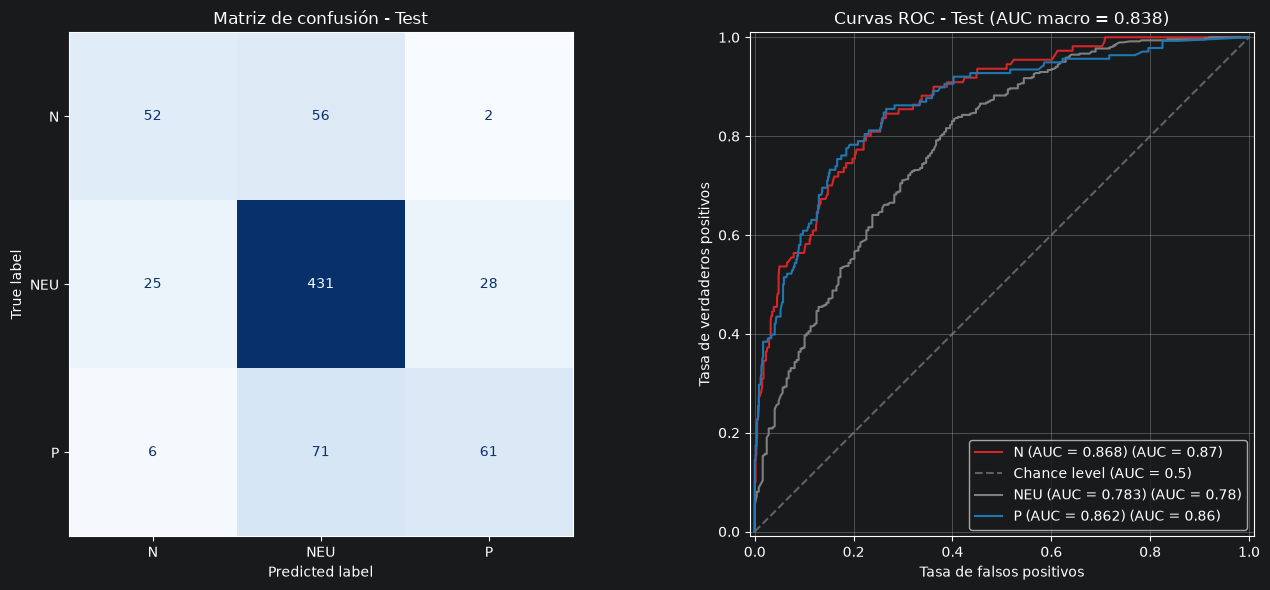

In [35]:
from sklearn.metrics import RocCurveDisplay
from sklearn.preprocessing import label_binarize

labels = ["N", "NEU", "P"]
colors = {"N": "#d62728", "NEU": "#7f7f7f", "P": "#1f77b4"}

for nombre, X_ev, y_ev in [("Test", X_test_prepro, y_test)]:
    y_pred = pipeline.predict(X_ev)
    probas = pipeline.predict_proba(X_ev)
    roc_auc = roc_auc_score(y_ev, probas, multi_class="ovr", average="macro")

    print("")
    print("===== " + nombre + " =====")
    print(f"f1_macro: {f1_score(y_ev, y_pred, average='macro'):.4f}   accuracy: {(y_pred == y_ev).mean():.4f}   ROC AUC: {roc_auc:.4f}")
    print(classification_report(y_ev, y_pred, labels=labels, digits=3))

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    cm = ConfusionMatrixDisplay.from_predictions(
        y_ev,
        y_pred,
        labels=labels,
        display_labels=labels,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=axes[0],
    )
    cm.ax_.set_title(f"Matriz de confusión - {nombre}")

    y_ev_bin = label_binarize(y_ev, classes=labels)
    for i, clase in enumerate(labels):
        RocCurveDisplay.from_predictions(
            y_ev_bin[:, i],
            probas[:, i],
            name=f"{clase} (AUC = {roc_auc_score(y_ev_bin[:, i], probas[:, i]):.3f})",
            ax=axes[1],
            plot_chance_level=(i == 0),
            chance_level_kw={"linestyle": "--", "color": "gray", "alpha": 0.7},
            curve_kwargs={"color": colors[clase]},
        )

    axes[1].set_title(f"Curvas ROC - {nombre} (AUC macro = {roc_auc:.3f})")
    axes[1].set_xlabel("Tasa de falsos positivos")
    axes[1].set_ylabel("Tasa de verdaderos positivos")
    axes[1].grid(True)

    fig.tight_layout()
    plt.show()


ROC AUC macro (OvR): 0.8378


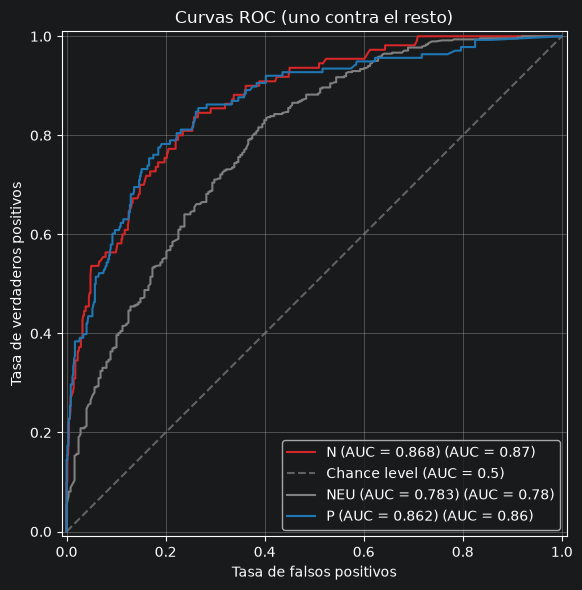

In [36]:
from sklearn.metrics import RocCurveDisplay
from sklearn.preprocessing import label_binarize

# El orden de las columnas de predict_proba es el de classes_
labels = list(pipeline.named_steps["classifier"].classes_)
colors = {"N": "#d62728", "NEU": "#7f7f7f", "P": "#1f77b4"}

probas = pipeline.predict_proba(X_test_prepro)
y_test_bin = label_binarize(y_test, classes=labels)

print(f"ROC AUC macro (OvR): {roc_auc_score(y_test, probas, multi_class='ovr', average='macro'):.4f}")

fig, ax = plt.subplots(figsize=(7, 6))

for i, clase in enumerate(labels):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        probas[:, i],
        name=f"{clase} (AUC = {roc_auc_score(y_test_bin[:, i], probas[:, i]):.3f})",
        ax=ax,
        plot_chance_level=(i == 0),
        chance_level_kw={"linestyle": "--", "color": "gray", "alpha": 0.7},
        curve_kwargs={"color": colors[clase]},
    )

ax.set_title("Curvas ROC (uno contra el resto)")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.grid(True)
fig.tight_layout()
plt.show()


In [37]:
# --- Prueba manual del pipeline ---
tweets = [
    "A veces funciona, a veces no",
    "Nos puede llegar a sacar el trabajo, es un peligro",
    "Es una buena herramienta",
]

# Valores numéricos neutros: mediana del train (no 0)
medianas = X_trval[number_columns].median()

entrada = pd.DataFrame({"text": tweets})
for col in number_columns:
    entrada[col] = medianas[col]

entrada_prepro = preprocessor.transform(entrada)

clf = pipeline.named_steps["classifier"]
preds = pipeline.predict(entrada_prepro)
probas = pipeline.predict_proba(entrada_prepro)

resultado = pd.DataFrame(probas, columns=clf.classes_).round(4)
resultado.insert(0, "tweet", tweets)
resultado.insert(1, "prediccion", preds)
print(resultado.to_string(index=False))

                                             tweet prediccion      N    NEU      P
                      A veces funciona, a veces no        NEU 0.3389 0.6611 0.0000
Nos puede llegar a sacar el trabajo, es un peligro          N 0.7765 0.2139 0.0096
                          Es una buena herramienta          P 0.0000 0.3521 0.6479
